# Run an Experiment

Config-first workflow:

1. Pick an experiment id from `configs/experiments/`.
2. Call `run_experiment(cfg)`. That's it.

To add a new experiment, drop a YAML into `configs/experiments/` — no code change.
Every run snapshots its fully-resolved config into `data/processed/xgboost_experiments/<id>/config_snapshot.json` so results are reproducible.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import load_config
from src.experiments.runner import run_experiment
from src.viz import make_all_plots


/Users/jaidonfroggatt-morton/miniforge3/envs/msc-dissertation-mots1-v2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Pick one and load it. Change this single line to switch experiments.
ACTIVE = 'exp_044_pa_ridge_student'  # CHANGE THIS
cfg = load_config(ACTIVE)

print(f'Loaded: {cfg.id}')
print(f'  description : {cfg.description}')
print(f'  hypothesis  : {cfg.hypothesis}')
print(f'  sections    : {cfg.run.sections}')
print(f'  trials      : {cfg.xgb.n_trials}')
print(f'  engineered  : {cfg.features.use_engineered}')
print(f'  results dir : {cfg.results_dir}') 

Loaded: exp_044_pa_ridge_student
  description : Varying-coefficient ridge student on the physics-augmented long format under the chemistry-standardised split.  The design matrix is composition + log_gamma + every composition-by-log_gamma product, so with the log1p target the model is a power-law surface whose consistency and flow-index are linear in composition (varying- coefficient model, Hastie & Tibshirani 1993, JRSS-B).  Motivated by the tl_chemistry study, where a per-shear ridge in log space reached pooled R-squared(log)=0.811 vs 0.753 for the XGBoost student: trees predict constants outside the training composition hull, while log-viscosity varies near-linearly with solids loading (Mooney 1951 -type concentration laws), so a linear-in-log-space student extrapolates correctly AND remains queryable at any shear rate.

  hypothesis  : The ridge student should match or beat the per-shear ridge's 0.811 pooled R-squared(log) while retaining the any-shear deployment capability the per

## Run

`run_experiment` loads splits, fits physics parameters for every model, and dispatches to each section listed in `cfg.run.sections`. Each run gets a unique directory under `data/processed/xgboost_experiments/` named `{experiment_id}_{YYYYMMDD_HHMMSS}`, so re-running the same config never overwrites previous results. The path is available as `results.results_dir`.

In [3]:
results = run_experiment(cfg)

ACTIVE EXPERIMENT: exp_044_pa_ridge_student
Description : Varying-coefficient ridge student on the physics-augmented long format under the chemistry-standardised split.  The design matrix is composition + log_gamma + every composition-by-log_gamma product, so with the log1p target the model is a power-law surface whose consistency and flow-index are linear in composition (varying- coefficient model, Hastie & Tibshirani 1993, JRSS-B).  Motivated by the tl_chemistry study, where a per-shear ridge in log space reached pooled R-squared(log)=0.811 vs 0.753 for the XGBoost student: trees predict constants outside the training composition hull, while log-viscosity varies near-linearly with solids loading (Mooney 1951 -type concentration laws), so a linear-in-log-space student extrapolates correctly AND remains queryable at any shear rate.

Hypothesis  : The ridge student should match or beat the per-shear ridge's 0.811 pooled R-squared(log) while retaining the any-shear deployment capability 

## Inspect results

`results` is an `ExperimentResults`: a dict of `SectionResult` objects keyed by section name. Every section has `model_summary`, `per_target`, and (optionally) `predictions` DataFrames.

In [4]:
for name, section in results.sections.items():
    print(f'--- {name} ---')
    display(section.sorted_by_r2().head())

print('Best (baseline/sweep/loo, first hit):', results.best())

--- physics_augmented ---


,variant,physics_oracle,learner,model_name,model_key,test_r2,test_r2_log,test_mae,test_rmse,n_test,n_aug_points,physics_model
0,sisko__ridge,sisko,ridge,sisko__ridge,sisko__ridge,0.359961,0.773862,8.950857,24.923235,132,30,sisko
1,power_law__ridge,power_law,ridge,power_law__ridge,power_law__ridge,0.333487,0.763892,9.006937,25.433477,132,30,power_law
2,cy5__ridge,cy5,ridge,cy5__ridge,cy5__ridge,0.330511,0.765728,9.043441,25.490185,132,30,cy5
3,williamson__ridge,williamson,ridge,williamson__ridge,williamson__ridge,0.328554,0.762447,9.084059,25.527412,132,30,williamson
4,constrained_cy__ridge,constrained_cy,ridge,constrained_cy__ridge,constrained_cy__ridge,0.318887,0.764858,8.971128,25.710515,132,30,constrained_cy


Best (baseline/sweep/loo, first hit): None


## Plots

In [5]:
if results.results_dir is None:
    print("Run was not persisted (persist=False) — no results directory to plot into.")
else:
    saved = make_all_plots(results, results.results_dir)
    for p in saved:
        print(p)

/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2 copy/data/processed/xgboost_experiments/exp_044_pa_ridge_student_20260613_140146/physics_augmented_model_comparison.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2 copy/data/processed/xgboost_experiments/exp_044_pa_ridge_student_20260613_140146/physics_augmented_per_target_r2_heatmap.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2 copy/data/processed/xgboost_experiments/exp_044_pa_ridge_student_20260613_140146/physics_augmented_variants.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2 copy/data/processed/xgboost_experiments/exp_044_pa_ridge_student_20260613_140146/physics_augmented_constrained_cy__ridge_predicted_vs_actual.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2 copy/data/processed/xgb

## Physics-augmented dataset visualisation

Only rendered when the active experiment uses the `physics_augmented` section.

* **Augmented dataset overview** — all training points (measured + augmented) on log-log axes, one subplot per physics oracle.  Shows how the 30 log-uniform samples per row fill the shear-rate space.
* **Sample flow curves** — 12 randomly sampled training rows showing the oracle-fitted curve (line) alongside the three measured viscosities (circles) on log-log axes.

Saved: /Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2 copy/data/processed/xgboost_experiments/exp_044_pa_ridge_student_20260613_140146/augmented_dataset_overview.png
Saved: /Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2 copy/data/processed/xgboost_experiments/exp_044_pa_ridge_student_20260613_140146/augmented_sample_curves.png


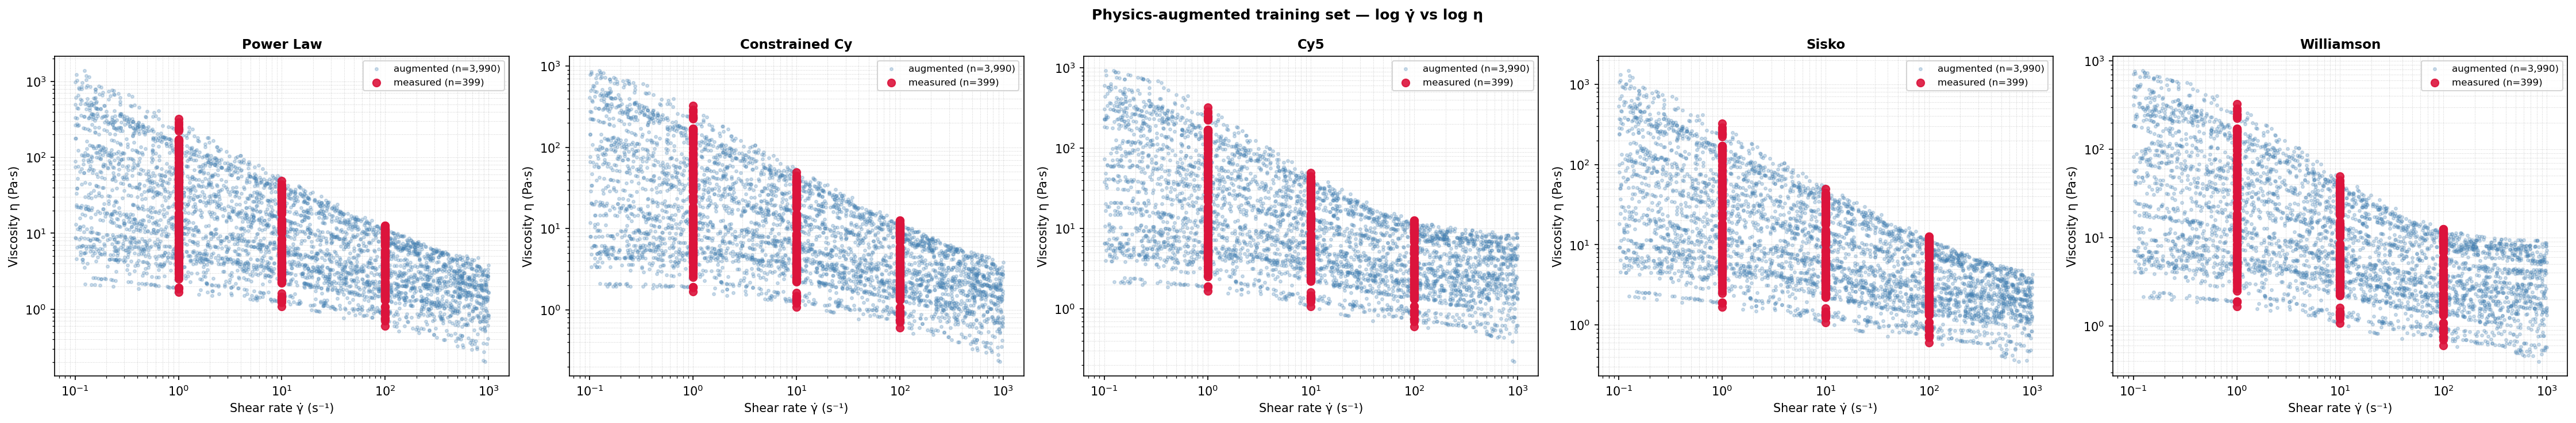

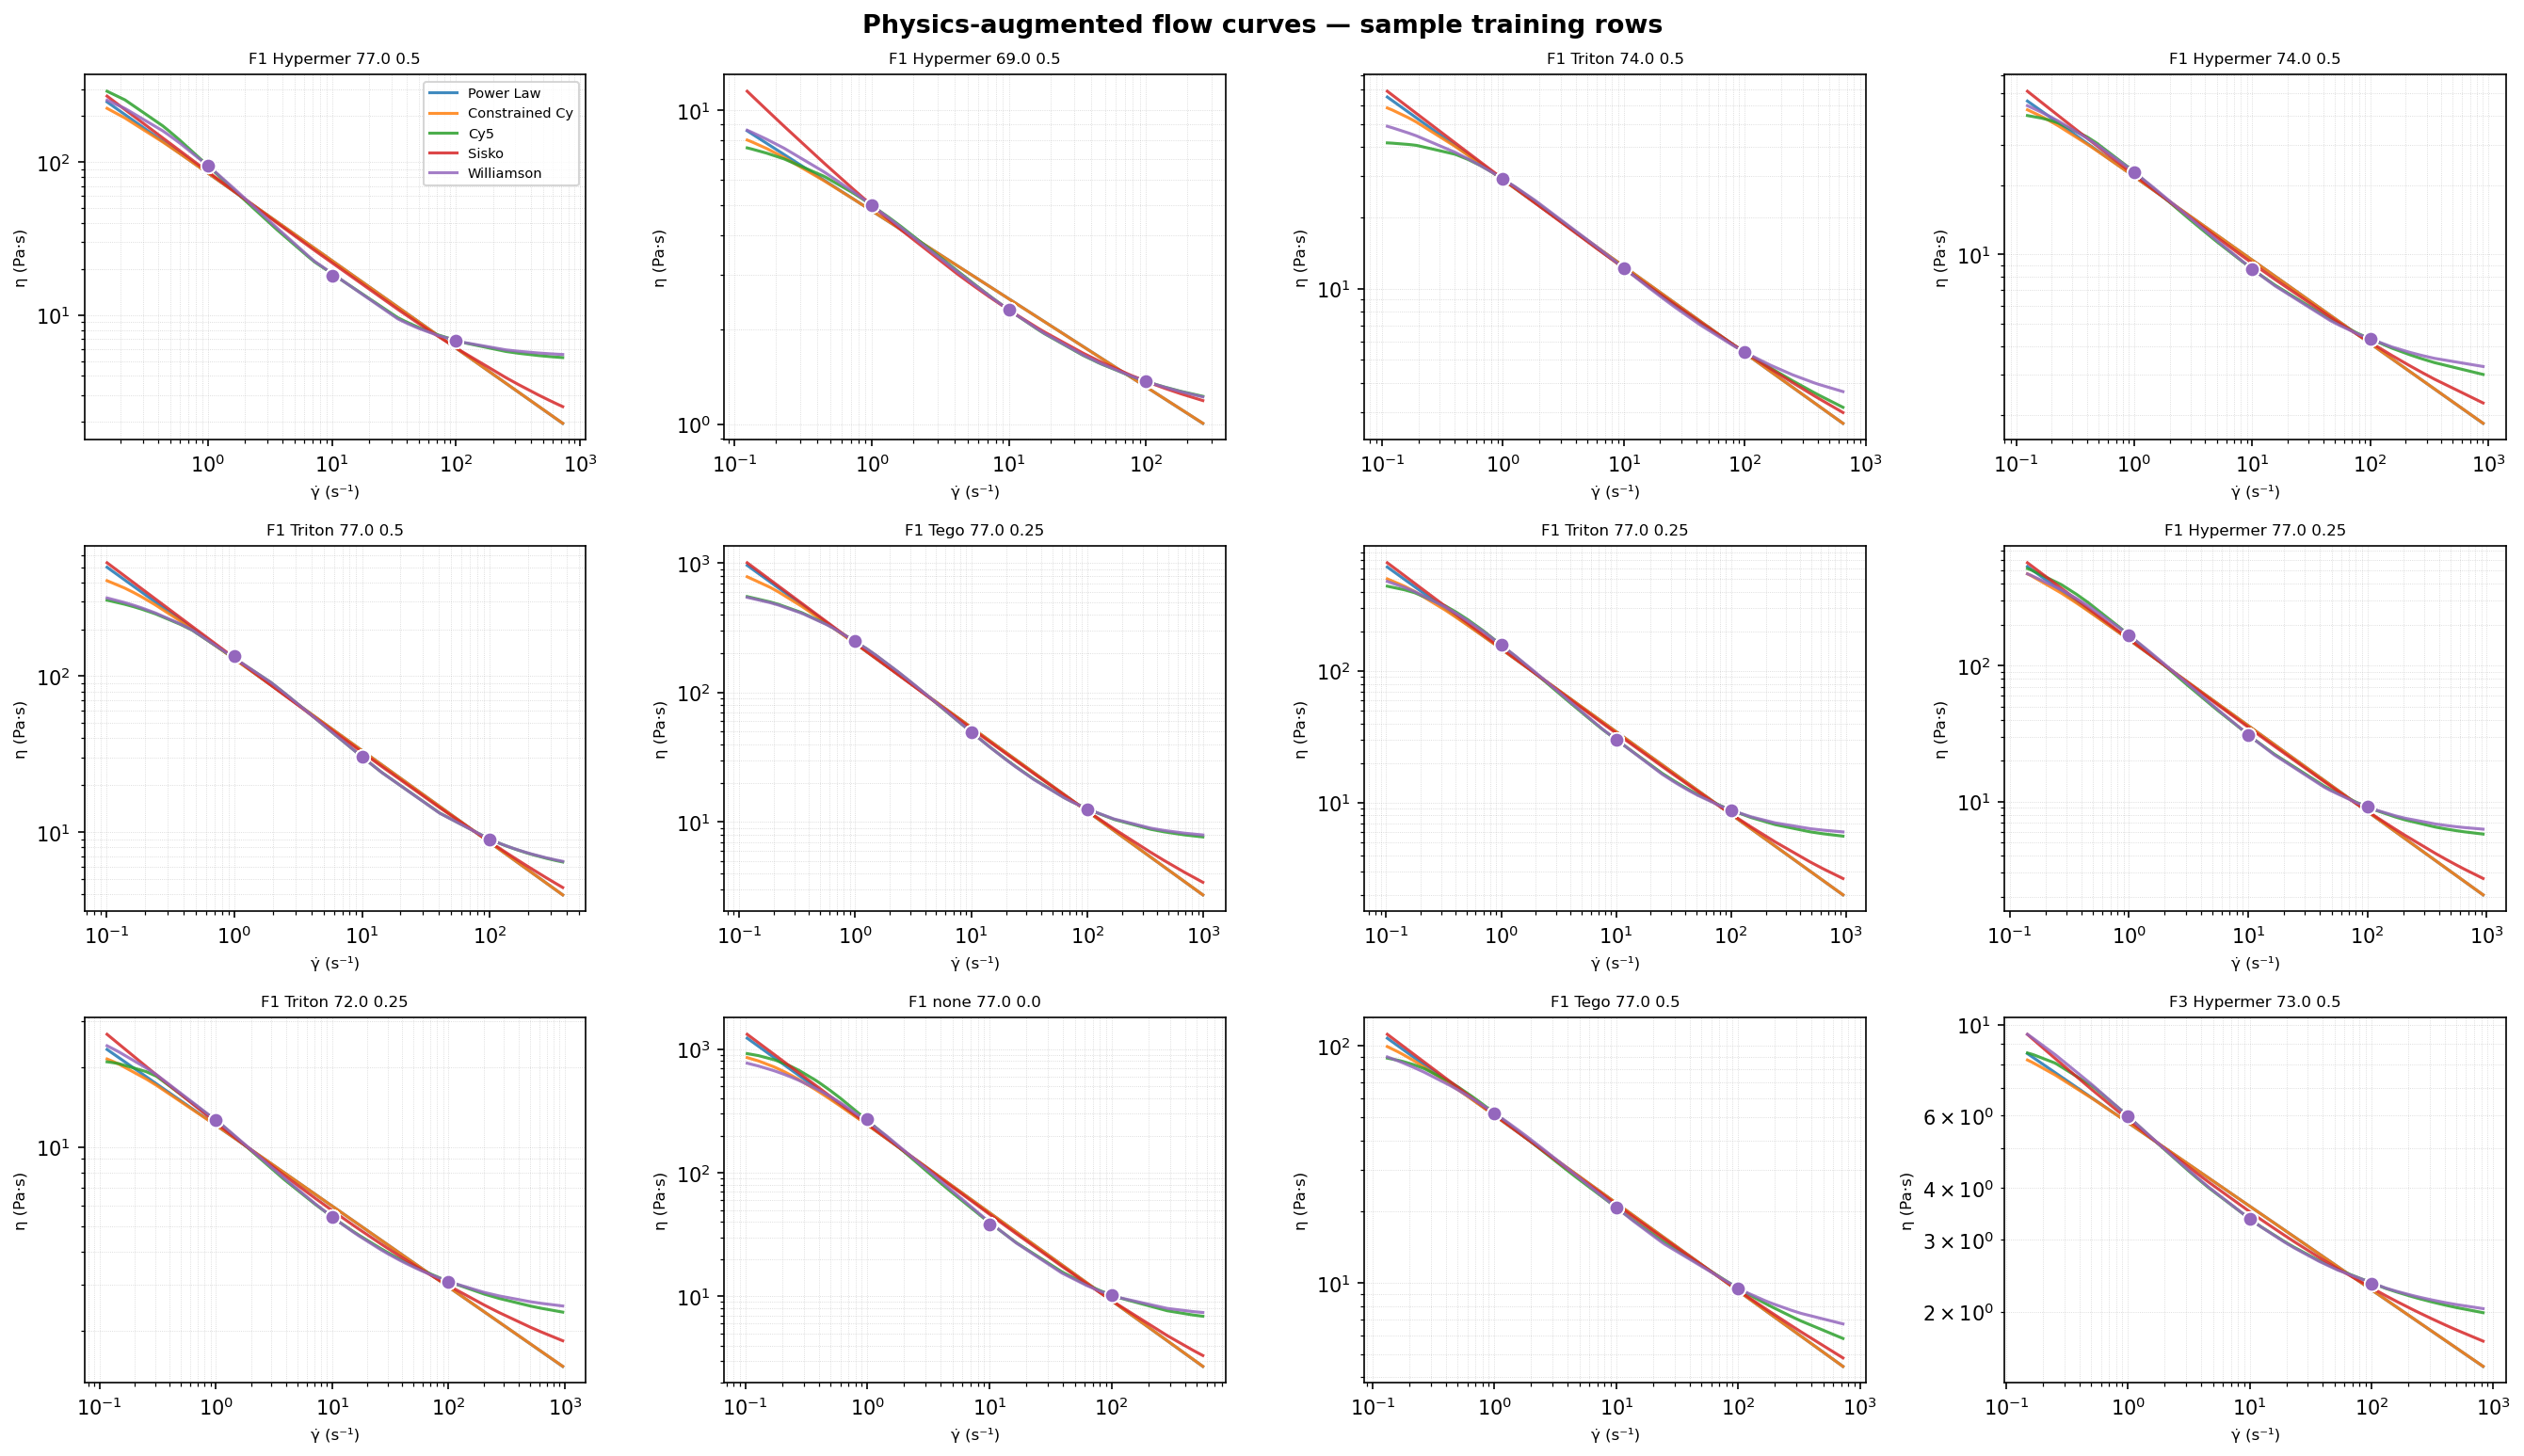

In [6]:
from IPython.display import Image, display as ipy_display

if 'physics_augmented' not in cfg.run.sections:
    print("Not a physics_augmented experiment — skip this cell.")
else:
    from src.data.splits import load_splits
    from src.physics_augmented.data import build_augmented_split
    from src.viz import plot_augmented_dataset_overview, plot_augmented_sample_curves

    pa_cfg = cfg.physics_augmented
    train_df, test_df = load_splits(cfg)

    splits = {}
    for model_key in pa_cfg.models:
        splits[model_key] = build_augmented_split(
            train_df=train_df,
            test_df=test_df,
            cfg=cfg,
            model_key=model_key,
            n_aug_points=int(pa_cfg.n_aug_points),
            shear_range=tuple(pa_cfg.shear_range),
            log_uniform=bool(pa_cfg.log_uniform_gamma),
            measured_weight=float(pa_cfg.measured_weight),
            seed=cfg.seed,
        )

    out_dir = results.results_dir or cfg.results_dir
    overview_path = plot_augmented_dataset_overview(splits, out_dir)
    curves_path   = plot_augmented_sample_curves(splits, out_dir, n_sample=12)

    print(f"Saved: {overview_path}")
    print(f"Saved: {curves_path}")
    ipy_display(Image(str(overview_path)))
    ipy_display(Image(str(curves_path)))

## Compare completed experiments

The `experiment_manifest.json` at the top of `data/processed/xgboost_experiments/` accumulates every run across the project.

In [7]:
import json
import pandas as pd

manifest_path = cfg.experiments_root_path / 'experiment_manifest.json'
if manifest_path.exists():
    runs = json.loads(manifest_path.read_text())['runs']
    df = pd.json_normalize(runs)
    cols = ['run_id', 'experiment_id', 'description', 'sections_run',
            'best.model_name', 'best.test_r2', 'duration_seconds', 'created_at_utc', 'notes']
    display(df[[c for c in cols if c in df.columns]])
else:
    print('No manifest yet. Run an experiment first.')

,run_id,experiment_id,description,sections_run,best.model_name,best.test_r2,duration_seconds,created_at_utc,notes
0,exp_044_pa_ridge_student_20260613_140146,exp_044_pa_ridge_student,Varying-coefficient ridge student on the physi...,[physics_augmented],NaN,NaN,7.1,2026-06-13T14:01:46.534802+00:00,
1,exp_043_pa_gpr_student_20260611_084051,exp_043_pa_gpr_student,GPR student on the physics-augmented long-form...,[physics_augmented],NaN,NaN,328.9,2026-06-11T08:40:51.789664+00:00,
2,exp_044_pa_ridge_student_20260611_084601,exp_044_pa_ridge_student,Varying-coefficient ridge student on the physi...,[physics_augmented],NaN,NaN,4.0,2026-06-11T08:46:01.980201+00:00,
3,exp_042_pa_monotone_crowding_20260611_084047,exp_042_pa_monotone_crowding,Combination of exp_040 (monotone-in-shear cons...,[physics_augmented],NaN,NaN,3.0,2026-06-11T08:40:47.772041+00:00,
4,exp_041_pa_crowding_feature_20260611_084043,exp_041_pa_crowding_feature,exp_035 (chemistry-standardised physics-augmen...,[physics_augmented],NaN,NaN,3.0,2026-06-11T08:40:43.746349+00:00,
...,...,...,...,...,...,...,...,...,...
94,exp_010_loo_only_20260421_152239,exp_010_loo_only,Leave-one-out generalisability evaluation (row...,[loo],Power Law,0.647151,264.2,2026-04-21T15:22:39.748376+00:00,
95,exp_004_trials_20_raw_20260421_145230,exp_004_trials_20_raw,Higher trials + raw features.,[baseline],Power Law,0.478763,68.5,2026-04-21T14:52:30.448196+00:00,
96,exp_003_raw_only_20260421_145112,exp_003_raw_only,Raw features only (no engineered features).,[baseline],Power Law,0.491317,30.6,2026-04-21T14:51:12.802008+00:00,
97,exp_002_trials_20_20260421_144927,exp_002_trials_20,Higher trial budget: 20 Optuna trials.,[baseline],Power Law,0.433388,70.1,2026-04-21T14:49:27.551810+00:00,


## Annotate a run

Add a free-text note to any completed run without re-running it.
Notes are saved into the manifest and each run's `metadata.json`.

```python
from src.experiments.results import annotate_run

annotate_run(
    run_id='<paste run_id from the table above>',
    note='Your observation here — e.g. Power Law best, CY5 overfit.',
    experiments_root=cfg.experiments_root_path,
)
```

Re-run the comparison cell above to see the note in the table.

In [8]:
from src.experiments.results import annotate_run

# Replace the run_id and note, then run this cell.
"""
annotate_run(
     run_id='exp_005_log_target_20260501_142410',
     note='attempted run without engineered features, to see if it would help with the log target. It did not.',
     experiments_root=cfg.experiments_root_path,
 )
"""

"\nannotate_run(\n     run_id='exp_005_log_target_20260501_142410',\n     note='attempted run without engineered features, to see if it would help with the log target. It did not.',\n     experiments_root=cfg.experiments_root_path,\n )\n"